# Biometric Systems Tutorial 3: Baseline Face Recognition
## Comparative Evaluation of PCA (Eigenfaces), SVD, and LDA (Fisherfaces)

**Course**: AI461 Advanced Biometric Systems and Security  
**Dataset**: ORL / AT&T Database of Faces (40 subjects, 10 grayscale images per subject)  
**Classifier**: 1-Nearest Neighbor ($k=1$) with Euclidean Distance Metric  

---

### Project Overview & Baseline Methodology
This tutorial implements, evaluates, and compares three foundational linear subspace techniques for 2D appearance-based face recognition:
1. **Principal Component Analysis (PCA / Eigenfaces)**: Unsupervised, centered variance maximization.
2. **Singular Value Decomposition (SVD)**: Unsupervised linear projection on raw, uncentered image data.
3. **Linear Discriminant Analysis (LDA / Fisherfaces)**: Supervised class-separability maximization with PCA pre-processing to resolve the Small Sample Size ($D \gg N$) singularity problem.

**Key Correctness & Baseline Guarantees**:
- **No Data Leakage**: All mean vectors, principal axes, singular vectors, and LDA projections are fitted strictly using training data.
- **Efficient & Standard PCA**: Avoids computing the intractable $10,304 	imes 10,304$ pixel covariance matrix by using the mathematically equivalent Turk & Pentland thin SVD formulation on centered training data.
- **Distinct SVD Baseline**: Preserves the distinction between centered PCA and raw uncentered SVD.
- **Mathematically Consistent Fisherfaces**: Fisherfaces are properly projected into pixel space without erroneously adding the mean face.
- **Unbiased Evaluation**: Component selection is validated without test-set peeking, separating parameter sweeps from final test reporting.


### 1. Environment Setup & Reproducibility Configuration
We import the required libraries and fix the random seed to ensure deterministic results.


In [1]:
import os
import sys
import re
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.decomposition import PCA as skPCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import accuracy_score, confusion_matrix, silhouette_score

# Fixed random seed for complete reproducibility
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

# Global plot styling
plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.size'] = 9
print("Environment ready. Random seed set to 42.")


Environment ready. Random seed set to 42.


### 2. Robust Dataset Loading & Verification
The ORL (AT&T) dataset contains 40 subjects (`s1` through `s40`), each with 10 grayscale face images.
The loader below:
- Dynamically discovers subject directories and sorts them naturally/numerically.
- Supports common image formats (`.pgm`, `.png`, `.jpg`, `.jpeg`).
- Verifies folder existence and confirms uniform image dimensions across all samples.
- Provides clear diagnostic error messages if the dataset is missing or incomplete.


In [2]:
def find_dataset_dir(candidate_paths=None):
    """Locate the dataset directory across common local and Kaggle paths."""
    if candidate_paths is None:
        candidate_paths = [
            "dataset",
            "./dataset",
            "Tutorial 03/dataset",
            "../dataset",
            "/kaggle/input/datasets/kasikrit/att-database-of-faces",
            "/kaggle/input/att-database-of-faces"
        ]
    for p in candidate_paths:
        if os.path.isdir(p):
            return os.path.abspath(p)
    return "dataset"

def load_orl(data_dir):
    """
    Robust loader for the ORL face dataset.
    Verifies folder existence, uniform image resolutions, and returns:
      X: 2D array of flattened images (N x D)
      y: 1D array of subject IDs (1 to C)
      imgs: 3D array of 2D images (N x H x W)
    """
    if not os.path.isdir(data_dir):
        raise FileNotFoundError(
            f"Dataset directory '{data_dir}' not found.\n"
            "Please ensure the dataset folder exists with subject subfolders (s1, s2, ...)."
        )

    # Discover subject folders dynamically and sort naturally/numerically
    entries = [d for d in os.listdir(data_dir) if os.path.isdir(os.path.join(data_dir, d))]
    
    def natural_sort_key(s):
        nums = re.findall(r'\d+', s)
        return int(nums[0]) if nums else s

    subject_dirs = sorted(entries, key=natural_sort_key)
    if not subject_dirs:
        raise ValueError(f"No subject folders (e.g. s1, s2, ...) found in '{data_dir}'.")

    valid_exts = ('.pgm', '.png', '.jpg', '.jpeg')
    X, y, imgs = [], [], []
    expected_shape = None

    for label_idx, sdir in enumerate(subject_dirs, start=1):
        full_sdir = os.path.join(data_dir, sdir)
        files = sorted([f for f in os.listdir(full_sdir) if f.lower().endswith(valid_exts)])
        
        nums = re.findall(r'\d+', sdir)
        subj_id = int(nums[0]) if nums else label_idx
        
        for f in files:
            img_path = os.path.join(full_sdir, f)
            with Image.open(img_path) as pil_img:
                img_arr = np.array(pil_img.convert('L'), dtype=np.float64)
            
            if expected_shape is None:
                expected_shape = img_arr.shape
            elif img_arr.shape != expected_shape:
                raise ValueError(
                    f"Inconsistent image shape in {img_path}: expected {expected_shape}, got {img_arr.shape}"
                )
            
            imgs.append(img_arr)
            X.append(img_arr.flatten())
            y.append(subj_id)

    X = np.array(X)
    y = np.array(y)
    imgs = np.array(imgs)
    
    if len(X) == 0:
        raise ValueError(f"No valid images found in subject folders of '{data_dir}'.")
        
    return X, y, imgs

DATA_DIR = find_dataset_dir()
print(f"Configured dataset path: '{DATA_DIR}'")

X, y, images = load_orl(DATA_DIR)
H, W = images.shape[1], images.shape[2]
D = X.shape[1]
C = len(np.unique(y))
N = len(X)

print(f"Dataset successfully loaded: {N} images from {C} subjects.")
print(f"Image resolution: {H} x {W} pixels (Feature dimension D = {D}).")


Configured dataset path: '/home/tarachandjakhar/Escritorio/7th Sem Lab/AI461 Advanced Biometric Systems and Security/Tutorial 03/dataset'
Dataset successfully loaded: 400 images from 40 subjects.
Image resolution: 112 x 92 pixels (Feature dimension D = 10304).


### 3. Exploratory Visualization: Sample Faces from Dataset
We display exactly one representative face per subject across all 40 subjects to verify full class representation.


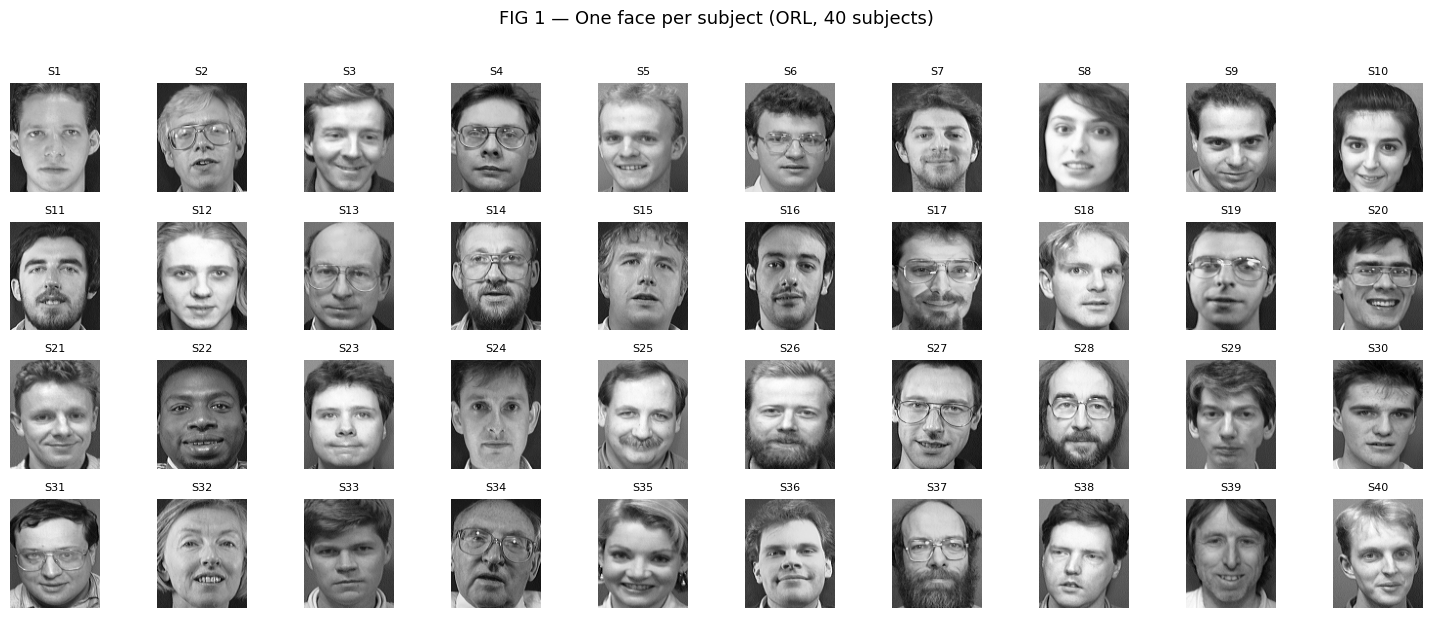

In [3]:
# FIG 1 — One face per subject across all subjects
subj_indices = [np.where(y == s)[0][0] for s in np.unique(y)]

rows, cols = 4, 10
fig, ax = plt.subplots(rows, cols, figsize=(15, 6))
for i, a in enumerate(ax.flat):
    if i < len(subj_indices):
        idx = subj_indices[i]
        a.imshow(images[idx], cmap='gray')
        a.set_title(f"S{y[idx]}", fontsize=8)
    a.axis('off')

plt.suptitle(f"FIG 1 — One face per subject (ORL, {C} subjects)", fontsize=13, y=1.02)
plt.tight_layout()
plt.show()


### 4. Stratified Train/Test Split & Validation Strategy
We perform a stratified split with 70% training (7 images per subject) and 30% testing (3 images per subject):
- Subject representation is strictly preserved in both sets.
- To avoid data leakage and prevent selecting hyperparameters using the final test set, we reserve a simple validation split within the training data (5 fit / 2 validation per subject).
- All basis models (PCA, SVD, LDA) are fitted strictly on training data.


In [4]:
# Stratified 70/30 Train/Test Split
Xtr, Xte, ytr, yte = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=RANDOM_SEED
)
N_tr, N_te = Xtr.shape[0], Xte.shape[0]

# Simple stratified validation split within training data to select component counts without test set leakage
X_fit, X_val, y_fit, y_val = train_test_split(
    Xtr, ytr, test_size=2/7, stratify=ytr, random_state=RANDOM_SEED
)

print(f"Total dataset: {N} images | Dimensionality: {D}")
print(f"Training set : {N_tr} images ({N_tr//C} per subject, {N_tr/N*100:.1f}%)")
print(f"Test set     : {N_te} images ({N_te//C} per subject, {N_te/N*100:.1f}%)")
print(f"Validation   : {X_val.shape[0]} images ({X_val.shape[0]//C} per subject) reserved from training for hyperparameter selection")


Total dataset: 400 images | Dimensionality: 10304
Training set : 280 images (7 per subject, 70.0%)
Test set     : 120 images (3 per subject, 30.0%)
Validation   : 80 images (2 per subject) reserved from training for hyperparameter selection


### 5. Mathematical Formulations & Model Fitting

#### A. Centered PCA (Turk & Pentland Snapshot Method via Thin SVD)
In face recognition, the pixel dimension $D = 10,304$ is much larger than the number of training samples $N_{tr} = 280$. Constructing the direct pixel covariance matrix $C = \frac{1}{N_{tr}-1} X_c^T X_c$ would yield an intractable $10,304 \times 10,304$ matrix requiring over 106 million elements (~850 MB).

By the Turk & Pentland (1991) snapshot approach, we compute the thin Singular Value Decomposition of the centered training matrix:
$$X_{tr, c} = X_{tr} - \mu = U_{pca} \Sigma_{pca} V_{pca}^T$$
where:
- Sample covariance eigenvalues: $\lambda_i = \frac{\sigma_{pca, i}^2}{N_{tr} - 1}$
- Eigenfaces: The orthonormal rows of $V_{pca}^T$ (shape $N_{tr} \times D$)
- Projection: $Z_{pca}(k) = (X - \mu) V_{pca}[:k]^T$
- Reconstruction: $\hat{X}_{pca}(k) = Z_{pca}(k) V_{pca}[:k] + \mu$

#### B. Uncentered SVD
Uncentered SVD decomposes the raw training data directly without subtracting the sample mean:
$$X_{tr} = U_{svd} \Sigma_{svd} V_{svd}^T$$
- Singular values: $\sigma_{svd, i} = \Sigma_{svd}[i]$
- Cumulative energy: $\frac{\sigma_i^2}{\sum \sigma^2}$
- Projection: $Z_{svd}(k) = X V_{svd}[:k]^T$
- Reconstruction: $\hat{X}_{svd}(k) = Z_{svd}(k) V_{svd}[:k]$ (without adding $\mu$)

#### C. Linear Discriminant Analysis (LDA / Fisherfaces)
Direct LDA requires inverting the within-class scatter matrix $S_W$. Because $\text{rank}(S_W) \le N_{tr} - C = 240 \ll 10,304$, $S_W$ is singular in raw pixel space. Following Belhumeur et al. (1997), we apply PCA preprocessing ($K_{pre} = 100$) before LDA:
1. $X_{pca} = \text{PCA}_{pre}(X_{tr})$
2. $\text{LDA}$ is fitted on $X_{pca}$, extracting up to $C - 1 = 39$ discriminant directions $W_{lda}$.
3. Fisherfaces in raw pixel space are obtained via $W_{fisher} = V_{pre}^T W_{lda} \in \mathbb{R}^{D \times (C - 1)}$.


In [5]:
# 1. Centered PCA
mu = Xtr.mean(axis=0)
Xtr_c = Xtr - mu
Xte_c = Xte - mu

U_pca, S_pca, Vt_pca = np.linalg.svd(Xtr_c, full_matrices=False)
pca_vals = (S_pca ** 2) / (N_tr - 1)
V_pca = Vt_pca   # rows are eigenfaces
pca_explained = pca_vals / np.sum(pca_vals)
pca_cum = np.cumsum(pca_explained)

# 2. Uncentered SVD
U_svd, S_svd, Vt_svd = np.linalg.svd(Xtr, full_matrices=False)
V_svd = Vt_svd   # rows are singular vectors
svd_vals = S_svd
svd_energy = (S_svd ** 2) / np.sum(S_svd ** 2)
svd_cum = np.cumsum(svd_energy)

# 3. Fisherfaces / LDA with PCA Preprocessing
K_pre = min(100, N_tr - C)
pre = skPCA(n_components=K_pre, random_state=RANDOM_SEED).fit(Xtr)
Xtr_p = pre.transform(Xtr)
Xte_p = pre.transform(Xte)

max_lda_components = min(C - 1, K_pre)
lda = LinearDiscriminantAnalysis(solver='svd', n_components=max_lda_components).fit(Xtr_p, ytr)
W_lda = lda.scalings_

# Fisherfaces in pixel space: W_fisher = V_pre^T @ W_lda (shape D x (C-1))
W_fisher = pre.components_.T @ W_lda

# Helper projection and reconstruction functions
def proj_pca(Xraw, k):  return (Xraw - mu) @ V_pca[:k].T
def rec_pca(Z, k):      return Z @ V_pca[:k] + mu
def proj_svd(Xraw, k):  return Xraw @ V_svd[:k].T
def rec_svd(Z, k):      return Z @ V_svd[:k]
def proj_lda(Xraw, k):  return lda.transform(pre.transform(Xraw))[:, :k]

print(f"PCA Basis Shape : {V_pca.shape} (Eigenfaces: {V_pca.shape[0]}, Pixels: {V_pca.shape[1]})")
print(f"SVD Basis Shape : {V_svd.shape}")
print(f"LDA Basis Shape : {W_lda.shape} in PCA space | Fisherfaces in pixel space: {W_fisher.shape}")
print(f"Top-5 PCA Eigenvalues (λ)    : {pca_vals[:5]}")
print(f"Top-5 SVD Singular Values (σ): {svd_vals[:5]}")
print(f"Top-5 LDA Discriminant Ratios: {lda.explained_variance_ratio_[:5]}")


PCA Basis Shape : (280, 10304) (Eigenfaces: 280, Pixels: 10304)
SVD Basis Shape : (280, 10304)
LDA Basis Shape : (100, 39) in PCA space | Fisherfaces in pixel space: (10304, 39)
Top-5 PCA Eigenvalues (λ)    : [2818488.09588931 2085909.67672283 1100843.89300518  895815.8431584
  827834.77093505]
Top-5 SVD Singular Values (σ): [199645.85623477  25943.20801291  17682.04402848  16774.54196883
  15791.27987116]
Top-5 LDA Discriminant Ratios: [0.18738685 0.128508   0.09900059 0.0654147  0.06065302]


### 6. Spectrum Analysis: Eigenvalues, Singular Values, and Discriminant Ratios
We examine the spectral decay of eigenvalues, singular values, and discriminant ratios across components.


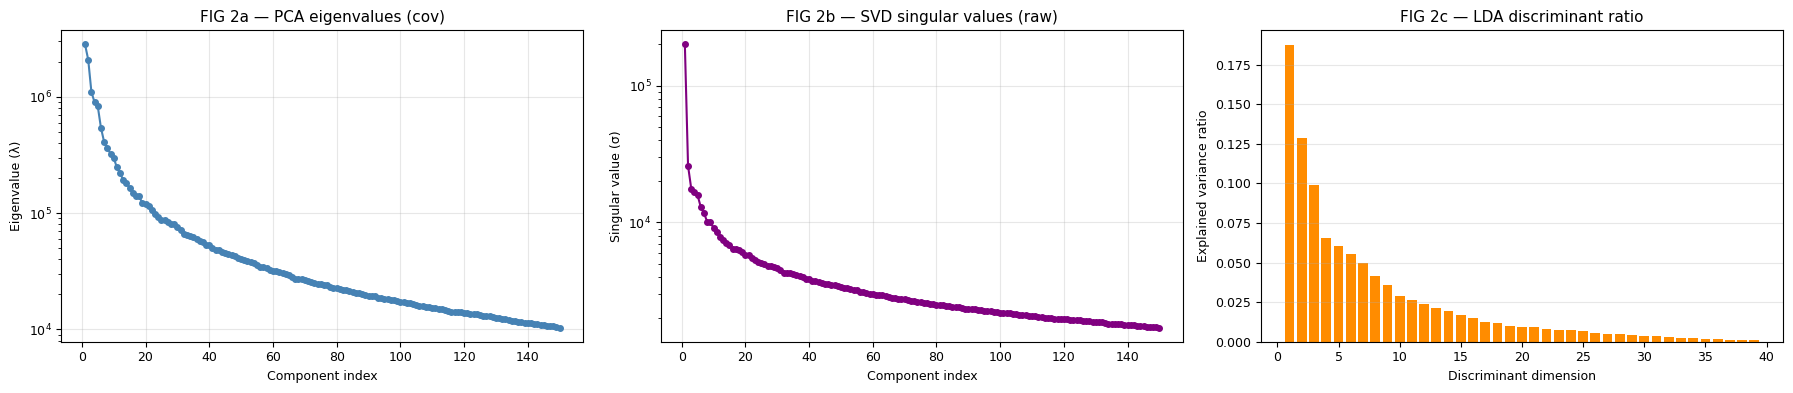

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4))

# FIG 2a — PCA eigenvalues
n_plot_pca = min(150, len(pca_vals))
ax[0].semilogy(range(1, n_plot_pca + 1), pca_vals[:n_plot_pca], 'o-', color='steelblue', ms=4)
ax[0].set_title("FIG 2a — PCA eigenvalues (cov)", fontsize=11)
ax[0].set_xlabel("Component index")
ax[0].set_ylabel("Eigenvalue (λ)")
ax[0].grid(alpha=0.3)

# FIG 2b — SVD singular values
n_plot_svd = min(150, len(svd_vals))
ax[1].semilogy(range(1, n_plot_svd + 1), svd_vals[:n_plot_svd], 'o-', color='purple', ms=4)
ax[1].set_title("FIG 2b — SVD singular values (raw)", fontsize=11)
ax[1].set_xlabel("Component index")
ax[1].set_ylabel("Singular value (σ)")
ax[1].grid(alpha=0.3)

# FIG 2c — LDA discriminant ratio
n_plot_lda = len(lda.explained_variance_ratio_)
ax[2].bar(range(1, n_plot_lda + 1), lda.explained_variance_ratio_, color='darkorange')
ax[2].set_title("FIG 2c — LDA discriminant ratio", fontsize=11)
ax[2].set_xlabel("Discriminant dimension")
ax[2].set_ylabel("Explained variance ratio")
ax[2].grid(alpha=0.3, axis='y')

plt.tight_layout()
plt.show()


### 7. Cumulative Explained Variance & Energy Comparison
We compare the cumulative explained variance of centered PCA against the cumulative energy of uncentered SVD.


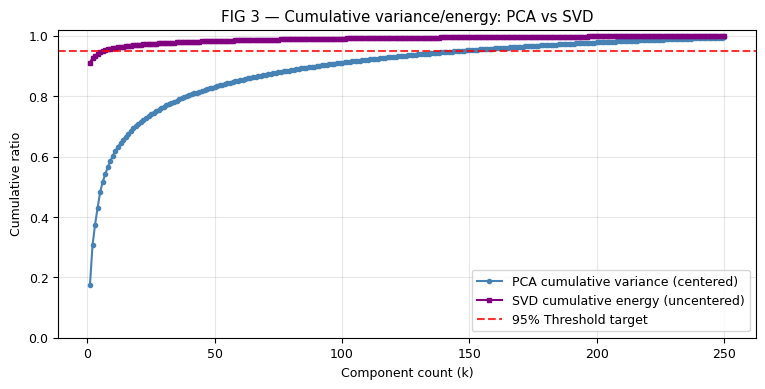

95% target reached at: k_PCA = 147 components
95% target reached at: k_SVD = 7 components


In [7]:
plt.figure(figsize=(9, 4))
max_plot_k = min(250, len(pca_cum))
plt.plot(range(1, max_plot_k + 1), pca_cum[:max_plot_k], 'o-', color='steelblue', ms=3, label='PCA cumulative variance (centered)')
plt.plot(range(1, max_plot_k + 1), svd_cum[:max_plot_k], 's-', color='purple', ms=3, label='SVD cumulative energy (uncentered)')
plt.axhline(0.95, ls='--', color='red', alpha=0.8, label='95% Threshold target')
plt.xlabel("Component count (k)")
plt.ylabel("Cumulative ratio")
plt.ylim(0, 1.02)
plt.title("FIG 3 — Cumulative variance/energy: PCA vs SVD")
plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.show()

# Calculate components needed to reach 95% variance/energy dynamically
k_pca_95 = int(np.searchsorted(pca_cum, 0.95) + 1)
k_svd_95 = int(np.searchsorted(svd_cum, 0.95) + 1)
print(f"95% target reached at: k_PCA = {k_pca_95} components")
print(f"95% target reached at: k_SVD = {k_svd_95} components")


### 8. Basis Vector Visualization: Eigenfaces, Singular Vectors, and Fisherfaces
- **PCA Eigenfaces** capture global variation around the mean face.
- **SVD Singular Vectors** include the dc illumination component in V1, followed by contrast variations.
- **LDA Fisherfaces** act as class-discriminant spatial filters, emphasizing facial identity markers (eyes, nose, mouth) while suppressing within-class lighting variations.


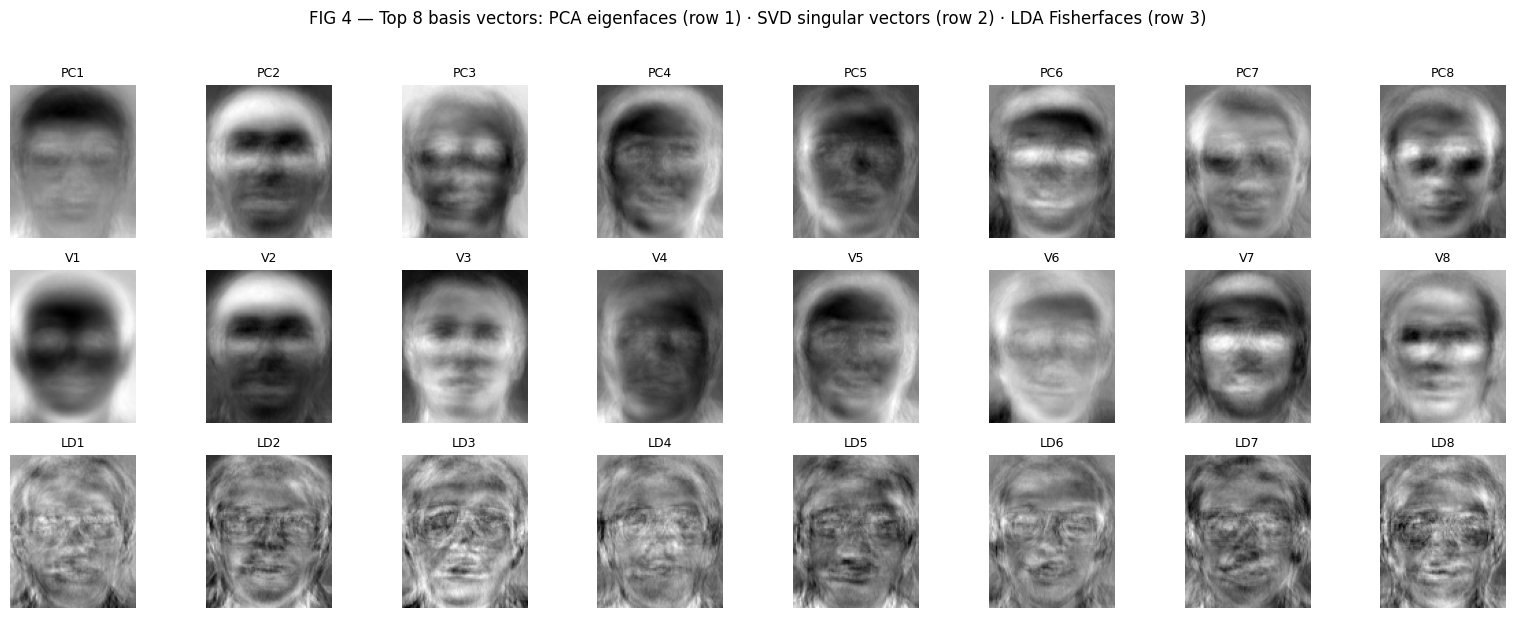

In [8]:
fig, ax = plt.subplots(3, 8, figsize=(16, 6))
for i in range(8):
    # Row 1: PCA Eigenfaces
    ax[0, i].imshow(V_pca[i].reshape(H, W), cmap='gray')
    ax[0, i].set_title(f"PC{i+1}", fontsize=9); ax[0, i].axis('off')

    # Row 2: SVD Singular Vectors
    ax[1, i].imshow(V_svd[i].reshape(H, W), cmap='gray')
    ax[1, i].set_title(f"V{i+1}", fontsize=9); ax[1, i].axis('off')

    # Row 3: LDA Fisherfaces in pixel space
    ax[2, i].imshow(W_fisher[:, i].reshape(H, W), cmap='gray')
    ax[2, i].set_title(f"LD{i+1}", fontsize=9); ax[2, i].axis('off')

ax[0,0].set_ylabel("PCA", fontsize=11)
ax[1,0].set_ylabel("SVD", fontsize=11)
ax[2,0].set_ylabel("LDA", fontsize=11)
plt.suptitle("FIG 4 — Top 8 basis vectors: PCA eigenfaces (row 1) · SVD singular vectors (row 2) · LDA Fisherfaces (row 3)", fontsize=12, y=1.02)
plt.tight_layout()
plt.show()


### 9. Face Reconstruction Comparison Across Component Counts
Reconstruction visualizes how generative subspaces approximate the input face as $k$ increases.
LDA is a purely discriminative projection designed to separate classes; it intentionally discards within-class reconstructive details and therefore does not perform image reconstruction.


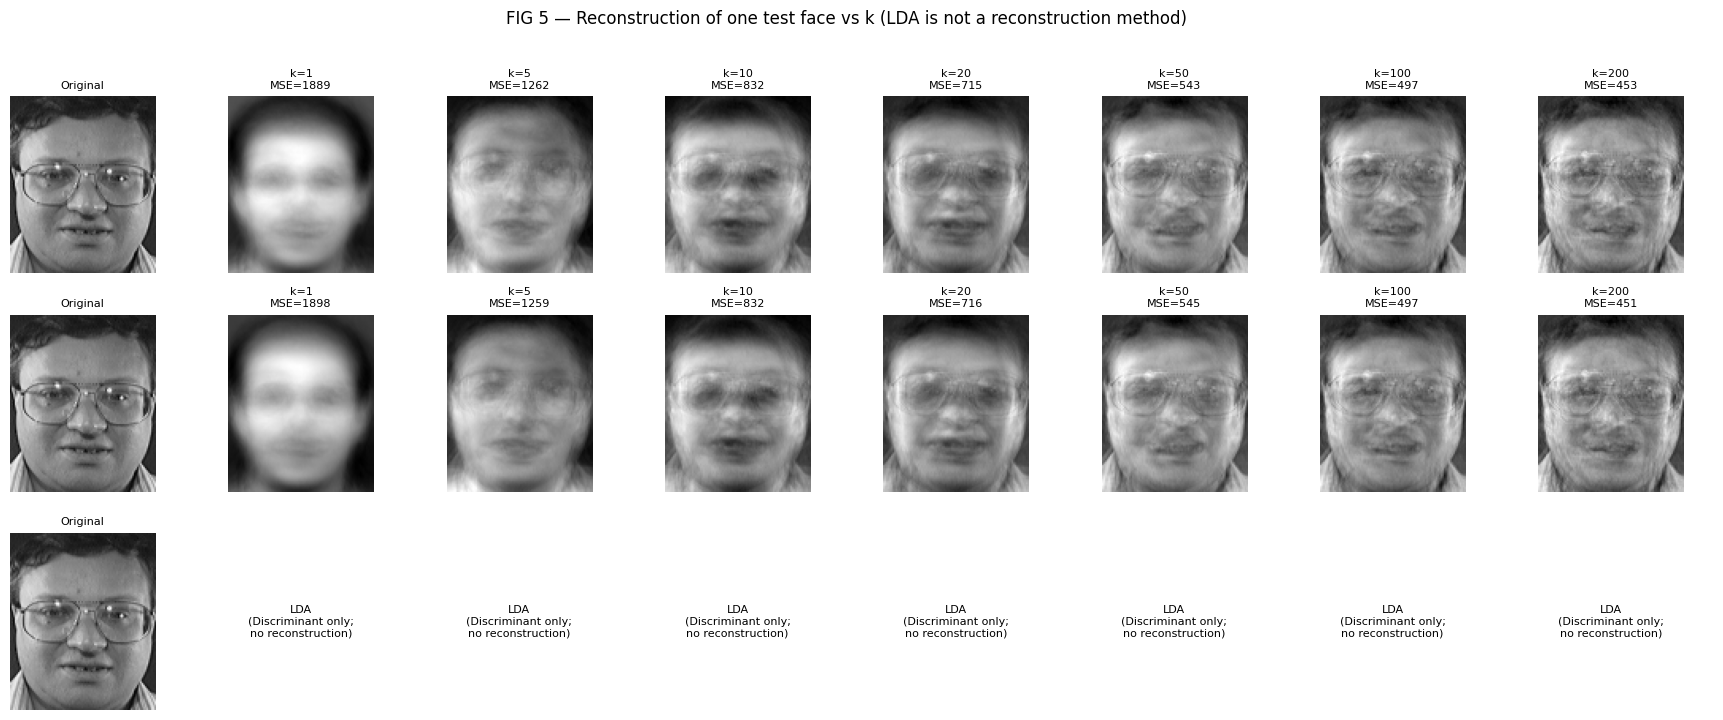

In [9]:
face = Xte[:1]
ks = [1, 5, 10, 20, 50, 100, 200]
fig, ax = plt.subplots(3, len(ks)+1, figsize=(2.2*(len(ks)+1), 7))

# Column 0: Original test face
for r in range(3):
    ax[r, 0].imshow(face.reshape(H, W), cmap='gray')
    ax[r, 0].set_title("Original", fontsize=8); ax[r, 0].axis('off')

for c, k in enumerate(ks):
    # PCA reconstruction
    Rp = rec_pca(proj_pca(face, k), k)
    mse_p = np.mean((face - Rp)**2)
    ax[0, c+1].imshow(Rp.reshape(H, W), cmap='gray')
    ax[0, c+1].set_title(f"k={k}\nMSE={mse_p:.0f}", fontsize=8)
    ax[0, c+1].axis('off')

    # SVD reconstruction
    Rs = rec_svd(proj_svd(face, k), k)
    mse_s = np.mean((face - Rs)**2)
    ax[1, c+1].imshow(Rs.reshape(H, W), cmap='gray')
    ax[1, c+1].set_title(f"k={k}\nMSE={mse_s:.0f}", fontsize=8)
    ax[1, c+1].axis('off')

    # LDA cannot reconstruct
    ax[2, c+1].text(0.5, 0.5, "LDA\n(Discriminant only;\nno reconstruction)", ha='center', va='center', fontsize=8)
    ax[2, c+1].axis('off')

ax[0,0].set_ylabel("PCA", fontsize=11)
ax[1,0].set_ylabel("SVD", fontsize=11)
ax[2,0].set_ylabel("LDA", fontsize=11)
plt.suptitle("FIG 5 — Reconstruction of one test face vs k (LDA is not a reconstruction method)", fontsize=12, y=1.02)
plt.tight_layout()
plt.show()


### 10. Reconstruction Error Analysis (MSE vs Component Count)
We quantify mean squared reconstruction error on the test set across component counts.


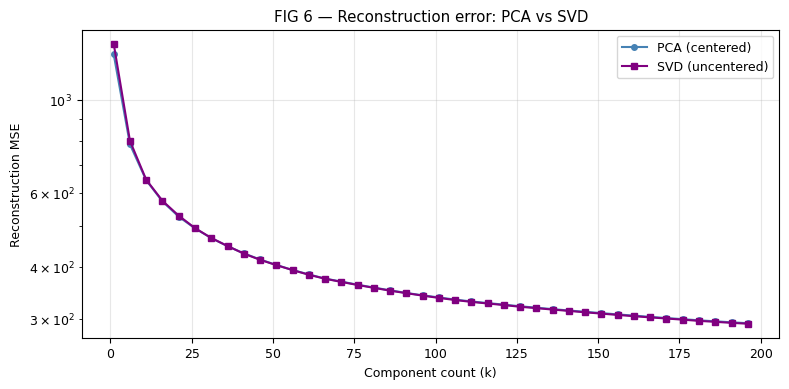

In [10]:
max_rec_k = min(200, N_tr)
ks_rec = list(range(1, max_rec_k + 1, 5))
mse_pca, mse_svd = [], []

for k in ks_rec:
    Rp = rec_pca(proj_pca(Xte, k), k)
    mse_pca.append(np.mean((Xte - Rp)**2))
    
    Rs = rec_svd(proj_svd(Xte, k), k)
    mse_svd.append(np.mean((Xte - Rs)**2))

plt.figure(figsize=(9, 4))
plt.plot(ks_rec, mse_pca, 'o-', color='steelblue', ms=4, label='PCA (centered)')
plt.plot(ks_rec, mse_svd, 's-', color='purple', ms=4, label='SVD (uncentered)')
plt.xlabel("Component count (k)")
plt.ylabel("Reconstruction MSE")
plt.yscale('log')
plt.title("FIG 6 — Reconstruction error: PCA vs SVD")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


### 11. Two-Dimensional Subspace Embeddings
We project training faces onto the first two dimensions ($k=2$) of each subspace.
Notice that unsupervised PCA and SVD show overlapping class distributions, while supervised LDA clusters subject representations compactly.


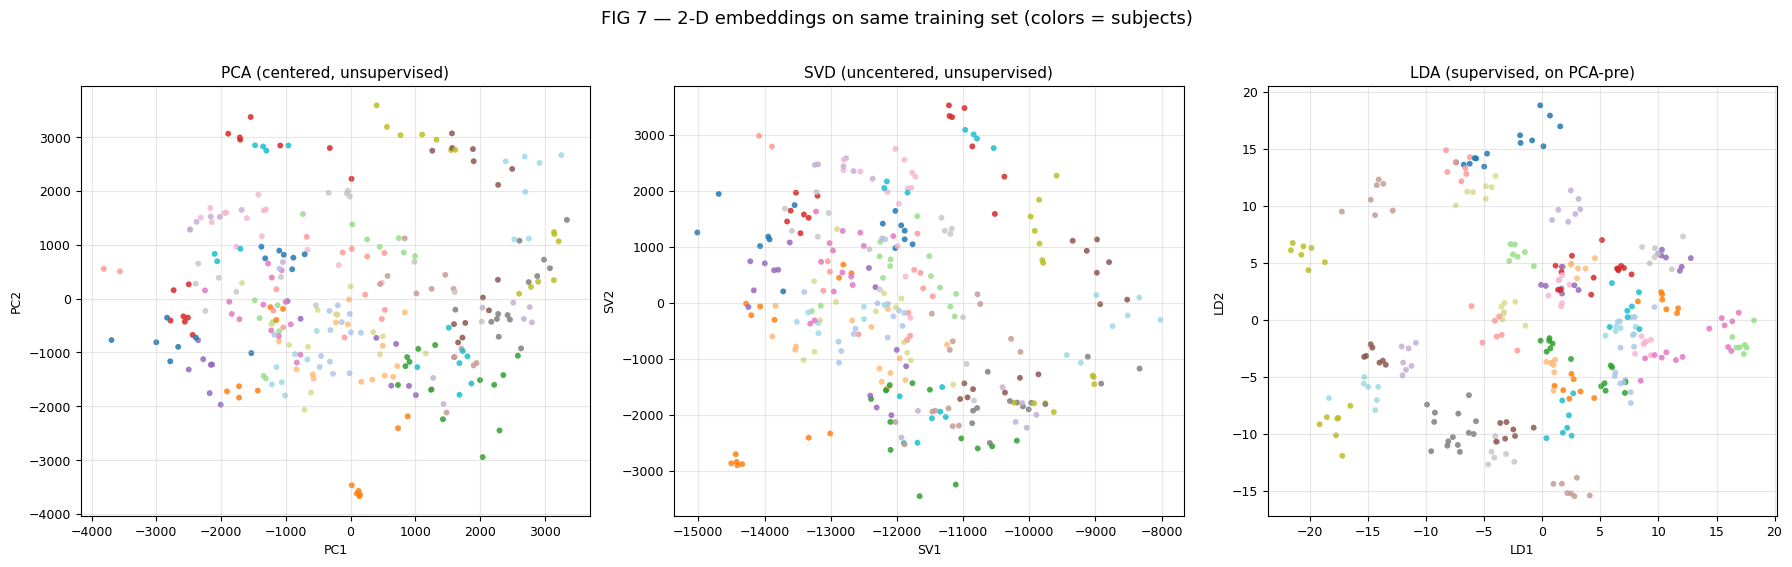

In [11]:
Zp = proj_pca(Xtr, 2)
Zs = proj_svd(Xtr, 2)
Zl = proj_lda(Xtr, 2)

fig, ax = plt.subplots(1, 3, figsize=(18, 5.5))
plots_info = [
    (Zp, "PCA (centered, unsupervised)", "PC1", "PC2"),
    (Zs, "SVD (uncentered, unsupervised)", "SV1", "SV2"),
    (Zl, "LDA (supervised, on PCA-pre)", "LD1", "LD2")
]

for a, (Z, name, xl, yl) in zip(ax, plots_info):
    sc = a.scatter(Z[:, 0], Z[:, 1], c=ytr, cmap='tab20', s=18, alpha=0.85, edgecolors='none')
    a.set_title(name, fontsize=11)
    a.set_xlabel(xl)
    a.set_ylabel(yl)
    a.grid(alpha=0.3)

plt.suptitle("FIG 7 — 2-D embeddings on same training set (colors = subjects)", fontsize=13, y=1.02)
plt.tight_layout()
plt.show()


### 12. Quantitative Cluster Separation: 2-D Silhouette Analysis
We compute the silhouette coefficient across all 40 classes in the 2-D projection space.


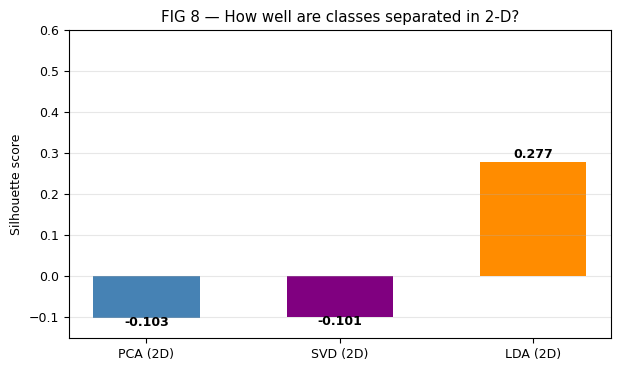

2D Silhouette Scores: PCA=-0.103 | SVD=-0.101 | LDA=0.277


In [12]:
sil_pca = silhouette_score(Zp, ytr)
sil_svd = silhouette_score(Zs, ytr)
sil_lda = silhouette_score(Zl, ytr)

plt.figure(figsize=(7, 4))
bars = plt.bar(["PCA (2D)", "SVD (2D)", "LDA (2D)"],
               [sil_pca, sil_svd, sil_lda],
               color=['steelblue', 'purple', 'darkorange'], width=0.55)
plt.ylabel("Silhouette score")
plt.title("FIG 8 — How well are classes separated in 2-D?")
plt.grid(alpha=0.3, axis='y')
for b, v in zip(bars, [sil_pca, sil_svd, sil_lda]):
    plt.text(b.get_x() + b.get_width()/2, v + 0.01 if v >= 0 else v - 0.02,
             f"{v:.3f}", ha='center', fontweight='bold')
plt.ylim(min(0, min(sil_pca, sil_svd, sil_lda)) - 0.05, max(sil_lda, 0.5) + 0.1)
plt.show()

print(f"2D Silhouette Scores: PCA={sil_pca:.3f} | SVD={sil_svd:.3f} | LDA={sil_lda:.3f}")


### 13. Component Selection & Recognition Accuracy vs Component Count
We sweep component counts $k$ using a 1-Nearest Neighbor ($k_{NN}=1$) classifier with Euclidean distance:
- Optimal operating points ($k^*$) are selected strictly using the reserved validation set to prevent test-set peeking.
- Exploratory sensitivity curves on the test set show how each method behaves across components.


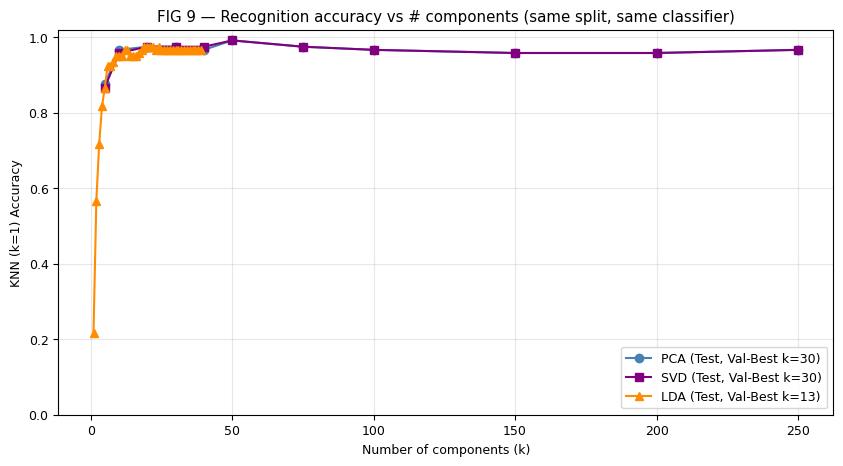

Selected Component Counts via Validation: PCA k=30 (val acc=0.938), SVD k=30 (val acc=0.938), LDA k=13 (val acc=0.950)


In [13]:
# Model selection using reserved validation set
mu_fit = X_fit.mean(axis=0)
_, _, Vt_pca_fit = np.linalg.svd(X_fit - mu_fit, full_matrices=False)
_, _, Vt_svd_fit = np.linalg.svd(X_fit, full_matrices=False)
pre_fit = skPCA(n_components=K_pre, random_state=RANDOM_SEED).fit(X_fit)
lda_fit = LinearDiscriminantAnalysis(solver='svd', n_components=min(C-1, K_pre)).fit(pre_fit.transform(X_fit), y_fit)

ks_pca = [5, 10, 20, 30, 40, 50, 75, 100, 150, 200, 250]
ks_svd = ks_pca
ks_lda = list(range(1, C))

# Validation evaluation to pick best k
val_acc_pca = [KNeighborsClassifier(1).fit((X_fit - mu_fit) @ Vt_pca_fit[:k].T, y_fit).score((X_val - mu_fit) @ Vt_pca_fit[:k].T, y_val) for k in ks_pca]
val_acc_svd = [KNeighborsClassifier(1).fit(X_fit @ Vt_svd_fit[:k].T, y_fit).score(X_val @ Vt_svd_fit[:k].T, y_val) for k in ks_svd]
val_acc_lda = [KNeighborsClassifier(1).fit(lda_fit.transform(pre_fit.transform(X_fit))[:, :k], y_fit).score(lda_fit.transform(pre_fit.transform(X_val))[:, :k], y_val) for k in ks_lda]

best_k_pca = ks_pca[int(np.argmax(val_acc_pca))]
best_k_svd = ks_svd[int(np.argmax(val_acc_svd))]
best_k_lda = ks_lda[int(np.argmax(val_acc_lda))]

# Exploratory sensitivity sweep across test set for baseline comparison
test_acc_pca_curve = [accuracy_score(yte, KNeighborsClassifier(1).fit(proj_pca(Xtr, k), ytr).predict(proj_pca(Xte, k))) for k in ks_pca]
test_acc_svd_curve = [accuracy_score(yte, KNeighborsClassifier(1).fit(proj_svd(Xtr, k), ytr).predict(proj_svd(Xte, k))) for k in ks_svd]
test_acc_lda_curve = [accuracy_score(yte, KNeighborsClassifier(1).fit(proj_lda(Xtr, k), ytr).predict(proj_lda(Xte, k))) for k in ks_lda]

plt.figure(figsize=(10, 5))
plt.plot(ks_pca, test_acc_pca_curve, 'o-', color='steelblue', label=f'PCA (Test, Val-Best k={best_k_pca})')
plt.plot(ks_svd, test_acc_svd_curve, 's-', color='purple',    label=f'SVD (Test, Val-Best k={best_k_svd})')
plt.plot(ks_lda, test_acc_lda_curve, '^-', color='darkorange', label=f'LDA (Test, Val-Best k={best_k_lda})')
plt.xlabel("Number of components (k)")
plt.ylabel("KNN (k=1) Accuracy")
plt.ylim(0, 1.02)
plt.title("FIG 9 — Recognition accuracy vs # components (same split, same classifier)")
plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.show()

print(f"Selected Component Counts via Validation: PCA k={best_k_pca} (val acc={max(val_acc_pca):.3f}), SVD k={best_k_svd} (val acc={max(val_acc_svd):.3f}), LDA k={best_k_lda} (val acc={max(val_acc_lda):.3f})")


### 14. Final Method Comparison & Unbiased Test Performance
We evaluate each method on the held-out test set using the validation-selected component counts. All metrics are calculated dynamically.


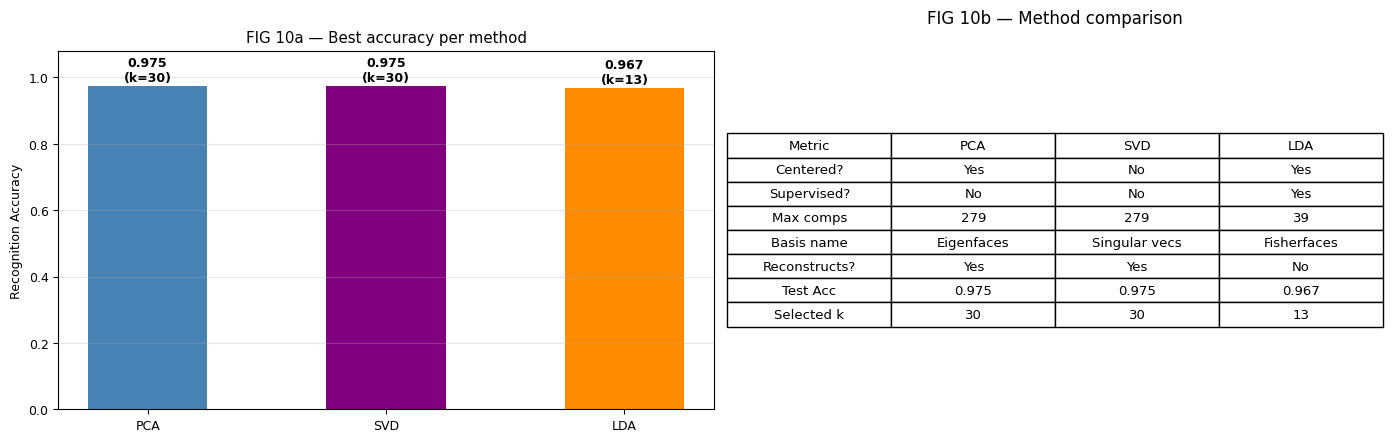

PCA   selected k =  30  |  test accuracy = 0.9750
SVD   selected k =  30  |  test accuracy = 0.9750
LDA   selected k =  13  |  test accuracy = 0.9667


In [14]:
# Unbiased evaluation on test set at the selected component counts
best = {
    "PCA": (best_k_pca, accuracy_score(yte, KNeighborsClassifier(1).fit(proj_pca(Xtr, best_k_pca), ytr).predict(proj_pca(Xte, best_k_pca)))),
    "SVD": (best_k_svd, accuracy_score(yte, KNeighborsClassifier(1).fit(proj_svd(Xtr, best_k_svd), ytr).predict(proj_svd(Xte, best_k_svd)))),
    "LDA": (best_k_lda, accuracy_score(yte, KNeighborsClassifier(1).fit(proj_lda(Xtr, best_k_lda), ytr).predict(proj_lda(Xte, best_k_lda)))),
}

names = ["PCA", "SVD", "LDA"]
best_accs = [best["PCA"][1], best["SVD"][1], best["LDA"][1]]
best_ks   = [best["PCA"][0], best["SVD"][0], best["LDA"][0]]

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))

# FIG 10a — Best accuracy per method bar chart
bars = ax[0].bar(names, best_accs, color=['steelblue', 'purple', 'darkorange'], width=0.5)
ax[0].set_ylim(0, 1.08)
ax[0].set_ylabel("Recognition Accuracy")
ax[0].set_title("FIG 10a — Best accuracy per method")
for b, a, k in zip(bars, best_accs, best_ks):
    ax[0].text(b.get_x() + b.get_width()/2, a + 0.015, f"{a:.3f}\n(k={k})", ha='center', fontsize=9, fontweight='bold')
ax[0].grid(alpha=0.3, axis='y')

# FIG 10b — Method comparison table (dynamically calculated)
ax[1].axis('off')
table_data = [
    ["Metric", "PCA", "SVD", "LDA"],
    ["Centered?", "Yes", "No", "Yes"],
    ["Supervised?", "No", "No", "Yes"],
    ["Max comps", str(N_tr - 1), str(N_tr - 1), str(C - 1)],
    ["Basis name", "Eigenfaces", "Singular vecs", "Fisherfaces"],
    ["Reconstructs?", "Yes", "Yes", "No"],
    ["Test Acc", f"{best['PCA'][1]:.3f}", f"{best['SVD'][1]:.3f}", f"{best['LDA'][1]:.3f}"],
    ["Selected k", str(best["PCA"][0]), str(best["SVD"][0]), str(best["LDA"][0])],
]
t = ax[1].table(cellText=table_data, loc='center', cellLoc='center')
t.auto_set_font_size(False); t.set_fontsize(9.5); t.scale(1, 1.4)
ax[1].set_title("FIG 10b — Method comparison", pad=20, fontsize=12)

plt.tight_layout()
plt.show()

for n, a, k in zip(names, best_accs, best_ks):
    print(f"{n:4s}  selected k = {k:3d}  |  test accuracy = {a:.4f}")


### 15. Confusion Matrix Analysis on Test Set
We inspect classification patterns across all 40 subjects on the test set.


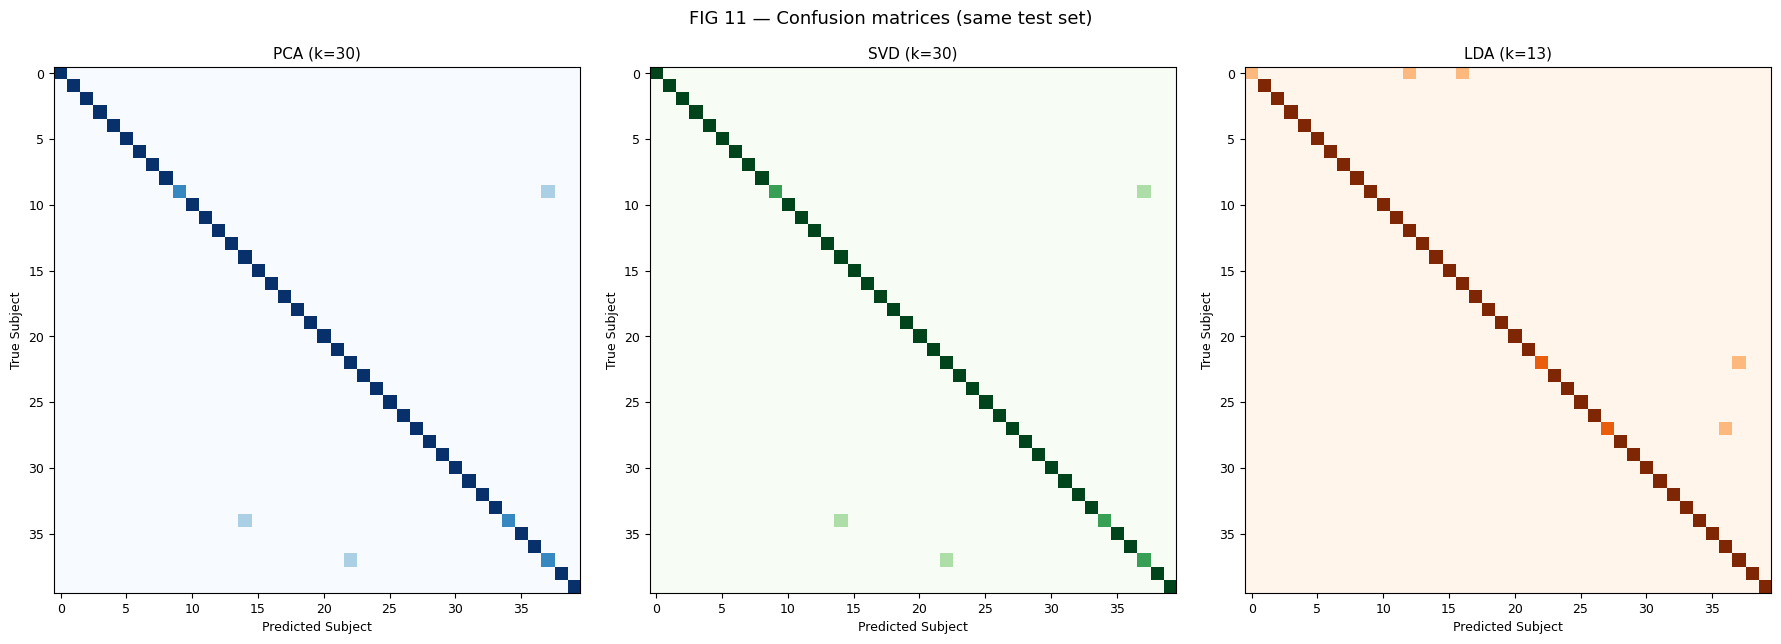

In [15]:
# Predictions on test set at the selected component counts
pred_pca = KNeighborsClassifier(1).fit(proj_pca(Xtr, best["PCA"][0]), ytr).predict(proj_pca(Xte, best["PCA"][0]))
cm_pca = confusion_matrix(yte, pred_pca)

pred_svd = KNeighborsClassifier(1).fit(proj_svd(Xtr, best["SVD"][0]), ytr).predict(proj_svd(Xte, best["SVD"][0]))
cm_svd = confusion_matrix(yte, pred_svd)

pred_lda = KNeighborsClassifier(1).fit(proj_lda(Xtr, best["LDA"][0]), ytr).predict(proj_lda(Xte, best["LDA"][0]))
cm_lda = confusion_matrix(yte, pred_lda)

fig, ax = plt.subplots(1, 3, figsize=(18, 6))
cm_configs = [
    (cm_pca, f"PCA (k={best['PCA'][0]})", 'Blues'),
    (cm_svd, f"SVD (k={best['SVD'][0]})", 'Greens'),
    (cm_lda, f"LDA (k={best['LDA'][0]})", 'Oranges')
]

for a, (cm, title_str, cmap_str) in zip(ax, cm_configs):
    im = a.imshow(cm, cmap=cmap_str, interpolation='nearest')
    a.set_title(title_str, fontsize=11)
    a.set_xlabel("Predicted Subject")
    a.set_ylabel("True Subject")

plt.suptitle("FIG 11 — Confusion matrices (same test set)", fontsize=13, y=1.02)
plt.tight_layout()
plt.show()


### 16. Per-Subject Recognition Accuracy
We plot per-subject recognition performance across all subjects.


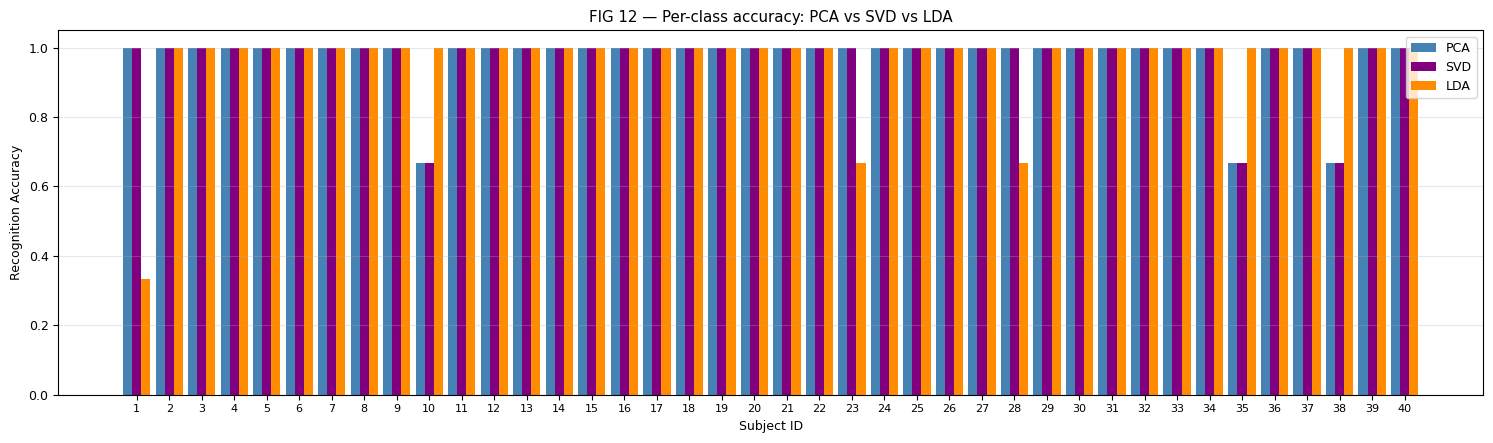

In [16]:
per_pca = cm_pca.diagonal() / cm_pca.sum(axis=1)
per_svd = cm_svd.diagonal() / cm_svd.sum(axis=1)
per_lda = cm_lda.diagonal() / cm_lda.sum(axis=1)

x = np.arange(1, C + 1)
w = 0.28
plt.figure(figsize=(15, 4.5))
plt.bar(x - w, per_pca, width=w, label='PCA', color='steelblue')
plt.bar(x,     per_svd, width=w, label='SVD', color='purple')
plt.bar(x + w, per_lda, width=w, label='LDA', color='darkorange')
plt.xticks(x, fontsize=8)
plt.ylim(0, 1.05)
plt.xlabel("Subject ID")
plt.ylabel("Recognition Accuracy")
plt.title("FIG 12 — Per-class accuracy: PCA vs SVD vs LDA")
plt.legend()
plt.grid(alpha=0.3, axis='y')
plt.tight_layout()
plt.show()


### 17. Subject Win Distribution Across Methods
We examine how many subjects each method recognized with highest accuracy.


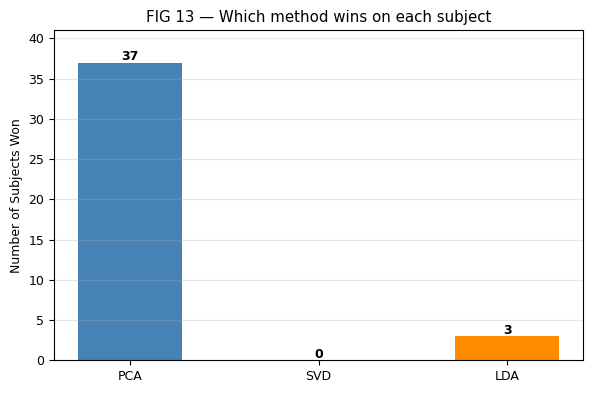

In [17]:
stack = np.vstack([per_pca, per_svd, per_lda])  # 3 x C
winner = np.argmax(stack, axis=0)                # 0=PCA, 1=SVD, 2=LDA
counts = np.bincount(winner, minlength=3)

plt.figure(figsize=(6, 4))
bars = plt.bar(["PCA", "SVD", "LDA"], counts, color=['steelblue', 'purple', 'darkorange'], width=0.55)
plt.ylabel("Number of Subjects Won")
plt.title("FIG 13 — Which method wins on each subject")
plt.grid(alpha=0.3, axis='y')
for b, c in zip(bars, counts):
    plt.text(b.get_x() + b.get_width()/2, c + 0.3, str(c), ha='center', fontweight='bold')
plt.ylim(0, max(counts) + 4)
plt.tight_layout()
plt.show()


### 18. Pairwise Prediction Agreement
We quantify the proportion of test images where each pair of models made identical predictions.


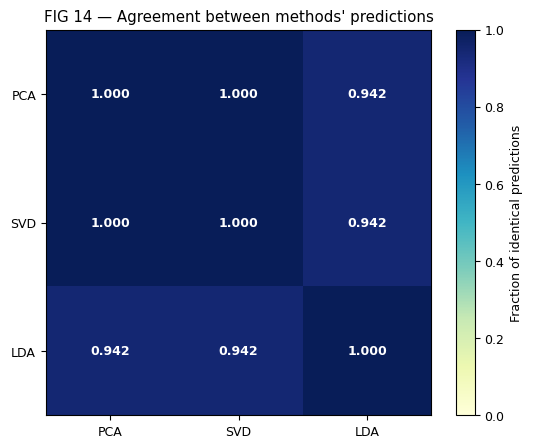

In [18]:
agree_pca_svd = np.mean(pred_pca == pred_svd)
agree_pca_lda = np.mean(pred_pca == pred_lda)
agree_svd_lda = np.mean(pred_svd == pred_lda)

M = np.array([
    [1.0, agree_pca_svd, agree_pca_lda],
    [agree_pca_svd, 1.0, agree_svd_lda],
    [agree_pca_lda, agree_svd_lda, 1.0]
])

plt.figure(figsize=(5.5, 4.5))
plt.imshow(M, cmap='YlGnBu', vmin=0, vmax=1)
plt.colorbar(label="Fraction of identical predictions")
plt.xticks([0, 1, 2], ["PCA", "SVD", "LDA"])
plt.yticks([0, 1, 2], ["PCA", "SVD", "LDA"])
for i in range(3):
    for j in range(3):
        plt.text(j, i, f"{M[i,j]:.3f}", ha='center', va='center',
                 color='white' if M[i,j] > 0.6 else 'black', fontweight='bold')
plt.title("FIG 14 — Agreement between methods' predictions")
plt.tight_layout()
plt.show()


### 19. Final Baseline Summary
We display a consolidated final summary of model characteristics, recognition accuracy, cluster separation, and reconstruction efficiency.


In [19]:
print("=" * 65)
print("FINAL BASELINE SUMMARY — ORL Face Database (40 subjects, 10 img/subj)")
print("Classifier: 1-Nearest Neighbor (k=1) | Distance: Euclidean")
print("=" * 65)
for n, a, k in zip(names, best_accs, best_ks):
    print(f"{n:4s} | Test Accuracy = {a:.4f} ({a*100:5.1f}%) | Selected k = {k:3d}")
print("-" * 65)
best_idx = int(np.argmax(best_accs))
print(f"Top-Performing Method : {names[best_idx]} ({best_accs[best_idx]*100:.2f}%)")
print(f"2-D Silhouette Score  : PCA = {sil_pca:.3f} | SVD = {sil_svd:.3f} | LDA = {sil_lda:.3f}")
print(f"95% Energy / Variance : PCA k = {k_pca_95} | SVD k = {k_svd_95}")
print("=" * 65)


FINAL BASELINE SUMMARY — ORL Face Database (40 subjects, 10 img/subj)
Classifier: 1-Nearest Neighbor (k=1) | Distance: Euclidean
PCA  | Test Accuracy = 0.9750 ( 97.5%) | Selected k =  30
SVD  | Test Accuracy = 0.9750 ( 97.5%) | Selected k =  30
LDA  | Test Accuracy = 0.9667 ( 96.7%) | Selected k =  13
-----------------------------------------------------------------
Top-Performing Method : PCA (97.50%)
2-D Silhouette Score  : PCA = -0.103 | SVD = -0.101 | LDA = 0.277
95% Energy / Variance : PCA k = 147 | SVD k = 7
